In [8]:
import matplotlib.pyplot as plt
import xarray as xr

time = ("2011-12", "2011-12")

observation_data = (
    xr.open_dataset("inputs/Processed_Johan_Buoys.nc")
    .sel(time=slice(time[0], time[1]))
    .resample(time="1H")
    .mean()
)
metamodel_data = xr.open_dataset("outputs/201112_500_spectra.nc").sel(
    time=slice(time[0], time[1])
)["__xarray_dataarray_variable__"]
dynamic_data = xr.open_dataset("outputs/Dynamic_Cases_201106_201112.nc").sel(
    time=slice(time[0], time[1])
)
era5_data = xr.open_dataset("inputs/ERA5_forcing_goals_2000_2025.nc").sel(
    time=slice(time[0], time[1])
)
codec_data = xr.open_dataset("inputs/CODEC_in_ERA5_coords.nc").sel(
    time=slice(time[0], time[1])
)

/home/tausiaj/miniforge3/envs/bluemath-311-dev/lib/python3.11/site-packages/xarray/groupers.py:530: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  self.index_grouper = pd.Grouper(


In [23]:
observation_data

<xarray.Dataset> Size: 221kB
Dimensions:       (time: 744, buoy: 9)
Coordinates:
  * time          (time) datetime64[ns] 6kB 2011-12-01 ... 2011-12-31T23:00:00
  * buoy          (buoy) int64 72B 8851 18354 16670 8991 ... 3075 16702 8226
    lon           (buoy) float64 72B 5.481 5.484 4.66 ... 4.996 6.367 4.158
    lat           (buoy) float64 72B 53.51 53.51 53.28 ... 53.32 53.62 52.05
    closest_goal  (buoy) int64 72B 4 4 6 8 7 7 6 2 8
Data variables:
    Hm0           (time, buoy) float64 54kB 1.483 1.28 2.493 ... 0.6517 nan
    Tm-10         (time, buoy) float64 54kB 5.233 5.5 6.25 5.567 ... 4.7 4.7 nan
    Th0           (time, buoy) float64 54kB 246.2 259.8 222.5 ... 281.0 nan
    depth         (time, buoy) float64 54kB -19.2 -19.3 -28.0 ... -14.8 -11.1
Attributes:
    projection:  ETRS89

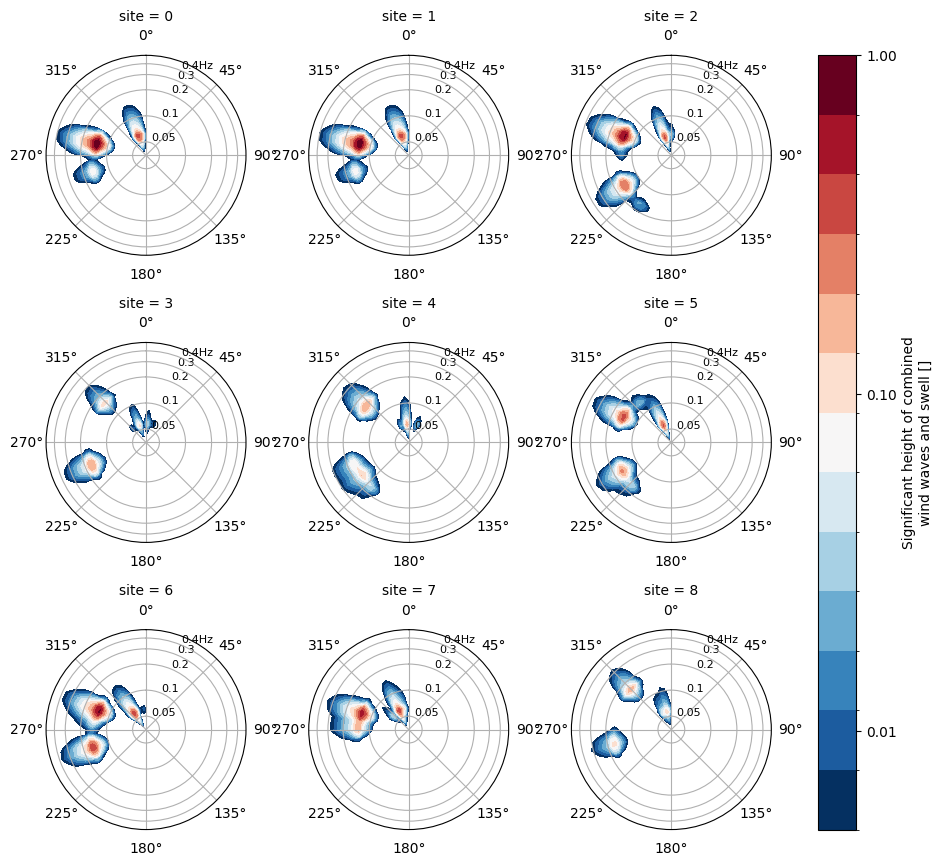

In [29]:
metamodel_data.isel(time=20).spec.plot(row="site", col_wrap=3)
plt.show()

In [25]:
observation_data.isel(buoy=0)["Tm-10"].plot()
metamodel_data.spec.tm().isel(site=0).plot()
plt.show()

AttributeError: 'SpecArray' object has no attribute 'tm'